# **Sony Stock: Cleaning, EDA, Visualization & Forecasting**



In [ ]:
import pandas as pd, numpy as np, warnings, os
warnings.filterwarnings('ignore')
import matplotlib.pyplot as plt, seaborn as sns
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller
sns.set_theme(style='whitegrid')
DATA = 'sony_stock_data.csv'
OUT = 'outputs/'; os.makedirs(OUT, exist_ok=True)

## 1. Load & clean

In [ ]:
df = pd.read_csv(DATA, parse_dates=['Date'])
print(df.shape); display(df.head()); display(df.dtypes)

(3179, 6)


,Date,Close,High,Low,Open,Volume
0,2014-01-02,3.203941,3.246884,3.189004,3.235681,13127000
1,2014-01-03,3.207675,3.222611,3.196472,3.213276,4642000
2,2014-01-06,3.230079,3.265554,3.224478,3.230079,11781500
3,2014-01-07,3.233814,3.245017,3.211409,3.241283,17191500
4,2014-01-08,3.407454,3.420523,3.222611,3.248750,42864500


Date      datetime64[us]
Close            float64
High             float64
Low              float64
Open             float64
Volume             int64
dtype: object

In [ ]:
# Data quality checks
report = {
    'rows': len(df),
    'duplicate_dates': int(df.Date.duplicated().sum()),
    'missing_values': int(df.isna().sum().sum()),
}
df = df.sort_values('Date').drop_duplicates('Date').reset_index(drop=True)
bad = (df.High < df[['Open','Close','Low']].max(axis=1) - 1e-6) | (df.Low > df[['Open','Close','High']].min(axis=1) + 1e-6)
report['ohlc_inconsistent'] = int(bad.sum())
report['zero_volume_days'] = int((df.Volume == 0).sum())
report['non_positive_prices'] = int((df[['Open','High','Low','Close']] <= 0).any(axis=1).sum())
report['gaps_over_5_days'] = int((df.Date.diff().dt.days > 5).sum())
df['Return'] = df.Close.pct_change()
report['abs_daily_return_over_12pct'] = int((df.Return.abs() > 0.12).sum())
pd.Series(report)

rows                           3179
duplicate_dates                   0
missing_values                    0
ohlc_inconsistent                 0
zero_volume_days                  0
non_positive_prices               0
gaps_over_5_days                  0
abs_daily_return_over_12pct       2
dtype: int64

In [ ]:
# Large moves: inspect, don't delete (they are real earnings-driven jumps with high volume)
df[df.Return.abs() > 0.12][['Date','Close','Return','Volume']]

,Date,Close,Return,Volume
522,2016-01-29,4.503216,0.176934,27585000
1784,2021-02-03,21.659964,0.121624,15131000


## 2. Feature engineering

In [ ]:
df['MA20'] = df.Close.rolling(20).mean()
df['MA50'] = df.Close.rolling(50).mean()
df['MA200'] = df.Close.rolling(200).mean()
df['Vol30'] = df.Return.rolling(30).std() * np.sqrt(252)   # annualised volatility
df['Drawdown'] = df.Close / df.Close.cummax() - 1
df['Year'] = df.Date.dt.year; df['Month'] = df.Date.dt.month
df['Turnover'] = df.Close * df.Volume

m = df.set_index('Date').resample('ME').agg(
    Open=('Open','first'), High=('High','max'), Low=('Low','min'),
    Close=('Close','last'), Volume=('Volume','sum'), Turnover=('Turnover','sum'))
m['Return'] = m.Close.pct_change()

y = df.groupby('Year').agg(Close=('Close','last'), Vol=('Return', lambda s: s.std()*np.sqrt(252)), AvgVolume=('Volume','mean'))
y['YoY'] = y.Close.pct_change()
y.loc[y.index[0], 'YoY'] = df[df.Year == y.index[0]].Close.iloc[-1] / df.Close.iloc[0] - 1
y.round(3)

,Close,Vol,AvgVolume,YoY
Year,,,,
2014,3.848,0.285,1.294573e+07,0.201
2015,4.641,0.335,7.721849e+06,0.206
2016,5.319,0.365,6.566956e+06,0.146
2017,8.579,0.227,4.226890e+06,0.613
2018,9.262,0.299,5.648434e+06,0.080
2019,13.142,0.274,6.530214e+06,0.419
2020,19.673,0.337,6.156049e+06,0.497
2021,24.717,0.282,3.652849e+06,0.256
2022,15.012,0.333,4.134102e+06,-0.393


## 3. Trend analysis (EDA)

In [ ]:
yrs = (df.Date.iloc[-1] - df.Date.iloc[0]).days / 365.25
tot = df.Close.iloc[-1] / df.Close.iloc[0]
vol = df.Return.std() * np.sqrt(252)
summary = {
    'Total return (x)': tot,
    'CAGR': tot**(1/yrs) - 1,
    'Annualised volatility': vol,
    'Sharpe (rf=0)': df.Return.mean()*252 / vol,
    'Max drawdown': df.Drawdown.min(),
    'Max drawdown date': df.loc[df.Drawdown.idxmin(), 'Date'].date(),
    'All-time high': df.Close.max(),
    'ATH date': df.loc[df.Close.idxmax(), 'Date'].date(),
    'Latest close': df.Close.iloc[-1],
    'Below ATH': df.Drawdown.iloc[-1],
    'Daily 5% VaR': df.Return.quantile(.05),
    'Return skew': df.Return.skew(), 'Return kurtosis': df.Return.kurt(),
}
pd.Series(summary)

Total return (x)           7.571926
CAGR                       0.173691
Annualised volatility      0.300295
Sharpe (rf=0)              0.683978
Max drawdown              -0.505593
Max drawdown date        2022-10-12
All-time high                 30.26
ATH date                 2025-11-12
Latest close                  24.26
Below ATH                 -0.198282
Daily 5% VaR              -0.027486
Return skew                0.499708
Return kurtosis            5.473592
dtype: object

In [ ]:
# Stationarity: prices are non-stationary, returns are stationary -> model differences (d=1)
print('ADF p-value, log price :', round(adfuller(np.log(df.Close))[1], 4))
print('ADF p-value, returns   :', round(adfuller(df.Return.dropna())[1], 4))
# Monthly seasonality
seas = m.groupby(m.index.month).Return.agg(mean='mean', median='median', pct_positive=lambda s: (s > 0).mean())
seas.round(4)

ADF p-value, log price : 0.4987


ADF p-value, returns   : 0.0


,mean,median,pct_positive
Date,,,
1,0.0219,0.0352,0.6154
2,0.0116,0.0228,0.5385
3,0.0131,0.0043,0.6154
4,-0.0025,-0.0295,0.3846
5,0.0280,0.0228,0.6923
6,0.0041,0.0317,0.5385
7,0.0670,0.0728,0.8462
8,0.0016,0.0009,0.5385
9,-0.0097,-0.0064,0.4167


## 4. Visualizations

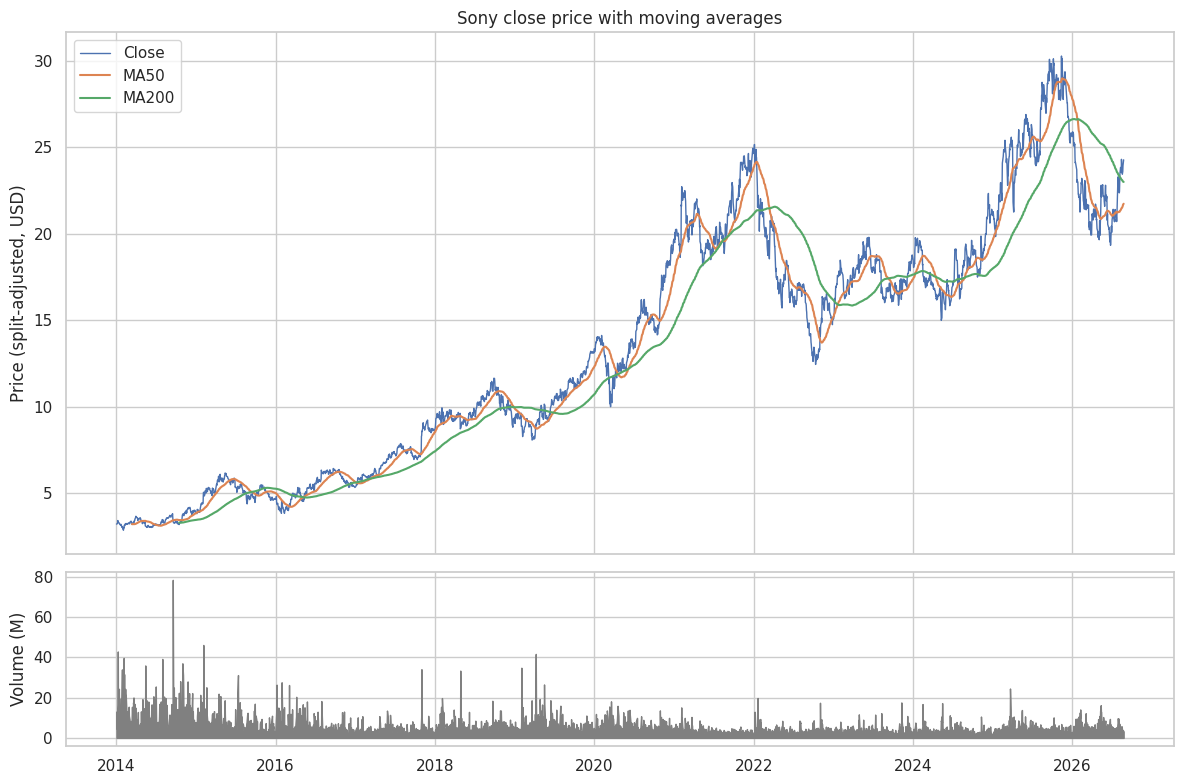

In [ ]:
fig, ax = plt.subplots(2, 1, figsize=(12, 8), sharex=True, gridspec_kw={'height_ratios': [3, 1]})
ax[0].plot(df.Date, df.Close, lw=1, label='Close'); ax[0].plot(df.Date, df.MA50, label='MA50'); ax[0].plot(df.Date, df.MA200, label='MA200')
ax[0].set_title('Sony close price with moving averages'); ax[0].set_ylabel('Price (split-adjusted, USD)'); ax[0].legend()
ax[1].fill_between(df.Date, df.Volume/1e6, color='gray'); ax[1].set_ylabel('Volume (M)')
plt.tight_layout(); plt.savefig(OUT+'01_price_trend.png', dpi=130); plt.show()

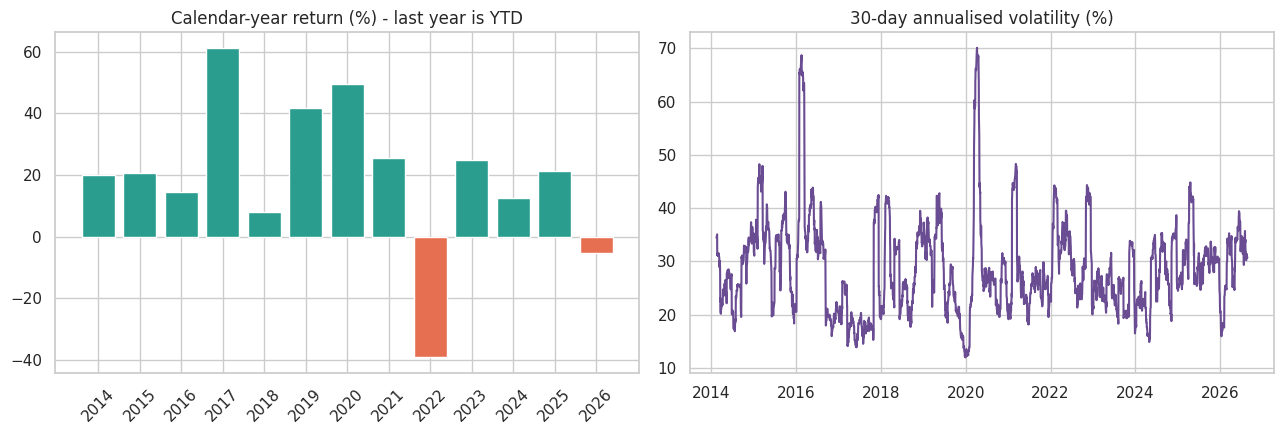

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].bar(y.index.astype(str), y.YoY*100, color=['#2a9d8f' if v > 0 else '#e76f51' for v in y.YoY])
ax[0].set_title('Calendar-year return (%) - last year is YTD'); ax[0].tick_params(axis='x', rotation=45)
ax[1].plot(df.Date, df.Vol30*100, color='#6a4c93'); ax[1].set_title('30-day annualised volatility (%)')
plt.tight_layout(); plt.savefig(OUT+'02_yearly_returns_volatility.png', dpi=130); plt.show()

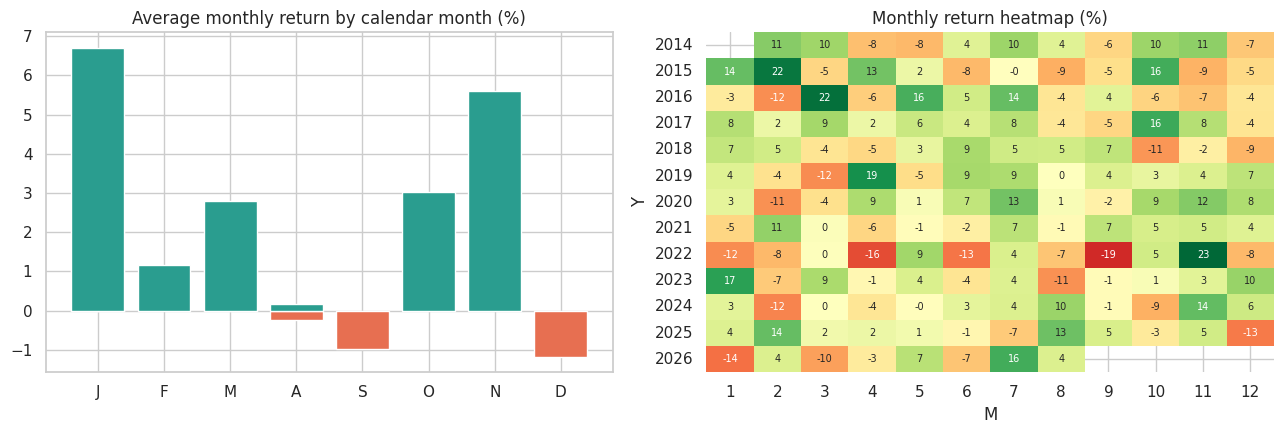

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sr = m.groupby(m.index.month).Return.mean() * 100
ax[0].bar(list('JFMAMJJASOND'), sr, color=['#2a9d8f' if v > 0 else '#e76f51' for v in sr]); ax[0].set_title('Average monthly return by calendar month (%)')
hm = m.assign(Y=m.index.year, M=m.index.month).pivot(index='Y', columns='M', values='Return') * 100
sns.heatmap(hm, cmap='RdYlGn', center=0, annot=True, fmt='.0f', cbar=False, ax=ax[1], annot_kws={'size': 7}); ax[1].set_title('Monthly return heatmap (%)')
plt.tight_layout(); plt.savefig(OUT+'03_monthly_seasonality.png', dpi=130); plt.show()

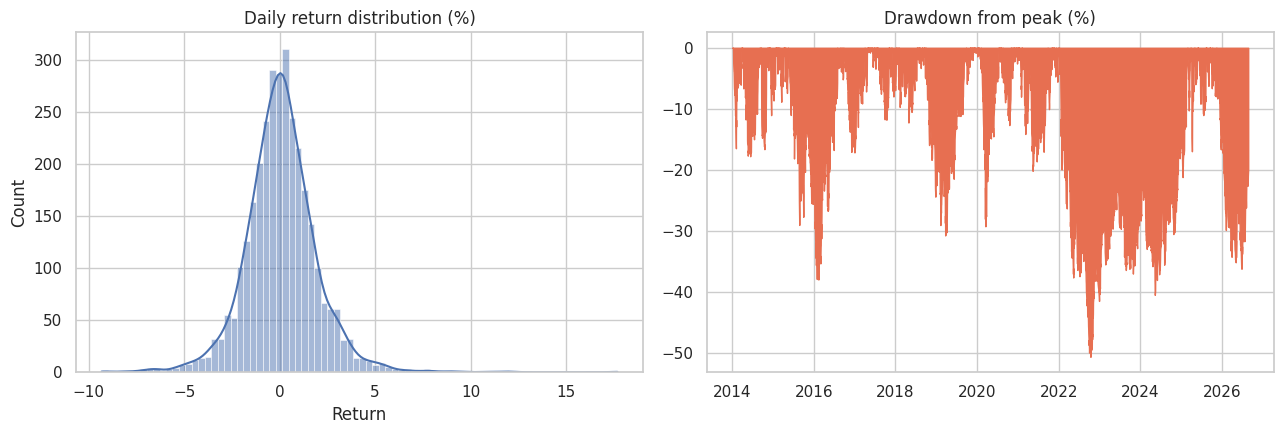

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(df.Return.dropna()*100, bins=80, kde=True, ax=ax[0]); ax[0].set_title('Daily return distribution (%)')
ax[1].fill_between(df.Date, df.Drawdown*100, color='#e76f51'); ax[1].set_title('Drawdown from peak (%)')
plt.tight_layout(); plt.savefig(OUT+'04_returns_drawdown.png', dpi=130); plt.show()

## 5. Forecasting (monthly closes, log scale)
Backtest: train on everything except the last 12 months, test on the last 12. Models: damped Holt, Holt-Winters (seasonal), ARIMA (order chosen by AIC), and a naive last-value baseline.

In [ ]:
s = np.log(m.Close); s.index = pd.PeriodIndex(s.index, freq='M').to_timestamp('M'); s.index.freq = 'ME'
h = 12
train, test = s.iloc[:-h], s.iloc[-h:]
mape = lambda a, f: np.mean(np.abs(np.exp(a) - np.exp(f)) / np.exp(a)) * 100

res = {}
res['Holt (damped)'] = ExponentialSmoothing(train, trend='add', damped_trend=True).fit().forecast(h)
res['Holt-Winters'] = ExponentialSmoothing(train, trend='add', damped_trend=True, seasonal='add', seasonal_periods=12).fit().forecast(h)

best = None
for o in [(p, 1, q) for p in range(4) for q in range(4)]:
    try:
        f = ARIMA(train, order=o).fit()
        if best is None or f.aic < best[0]: best = (f.aic, o, f)
    except Exception: pass
print('Best ARIMA order by AIC:', best[1])
res[f'ARIMA{best[1]}'] = best[2].forecast(h)
res['Naive (last value)'] = pd.Series(train.iloc[-1], index=test.index)

backtest = pd.DataFrame({k: {'MAPE %': mape(test, v), 'RMSE (log)': np.sqrt(np.mean((test - v)**2))} for k, v in res.items()}).T.round(3)
backtest

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


Best ARIMA order by AIC: (2, 1, 2)


/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


,MAPE %,RMSE (log)
Holt (damped),24.324,0.245
Holt-Winters,24.053,0.240
"ARIMA(2, 1, 2)",18.194,0.187
Naive (last value),19.150,0.199


In [ ]:
# Refit on all data and forecast the next 12 months
arima = ARIMA(s, order=best[1]).fit()
fc = arima.get_forecast(h); ci = fc.conf_int(alpha=0.2)
fc_df = pd.DataFrame({
    'ARIMA': np.exp(fc.predicted_mean), 'ARIMA_lo80': np.exp(ci.iloc[:, 0]), 'ARIMA_hi80': np.exp(ci.iloc[:, 1]),
    'Holt': np.exp(ExponentialSmoothing(s, trend='add', damped_trend=True).fit().forecast(h)),
    'HoltWinters': np.exp(ExponentialSmoothing(s, trend='add', damped_trend=True, seasonal='add', seasonal_periods=12).fit().forecast(h)),
})
fc_df.index.name = 'MonthEnd'
fc_df.round(2)

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


,ARIMA,ARIMA_lo80,ARIMA_hi80,Holt,HoltWinters
MonthEnd,,,,,
2026-09-30,23.66,21.40,26.17,24.25,23.75
2026-10-31,24.86,21.62,28.58,24.38,24.16
2026-11-30,23.98,20.19,28.48,24.51,25.21
2026-12-31,23.87,19.56,29.12,24.63,24.63
2027-01-31,24.88,19.94,31.04,24.76,24.85
2027-02-28,23.75,18.63,30.29,24.89,24.76
2027-03-31,24.13,18.56,31.37,25.01,24.75
2027-04-30,24.79,18.73,32.80,25.14,24.36
2027-05-31,23.61,17.53,31.80,25.26,24.76


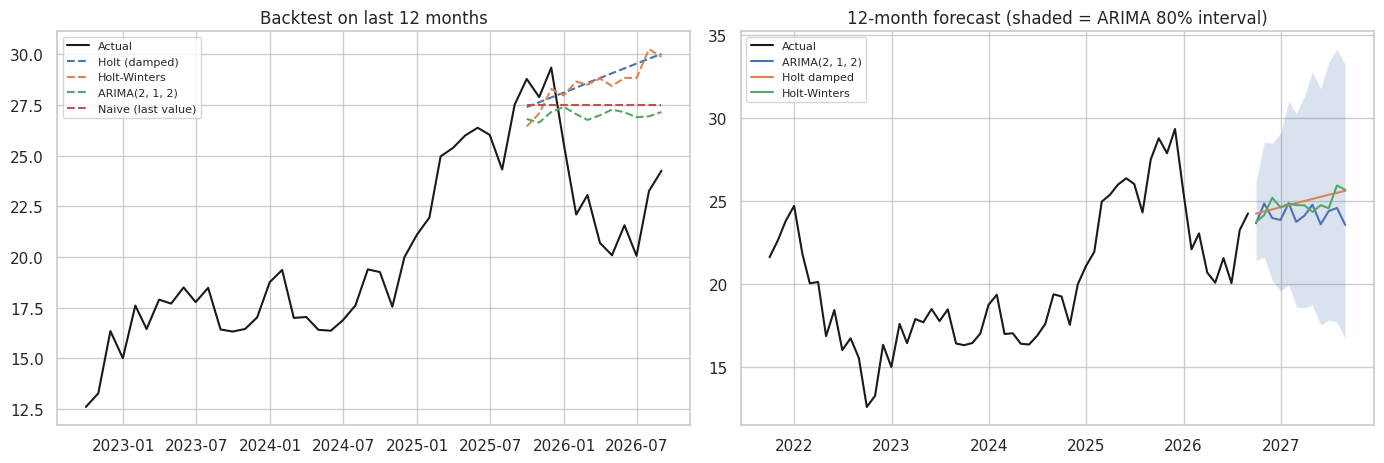

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
ax[0].plot(np.exp(s.iloc[-48:]), label='Actual', color='k')
for k, v in res.items(): ax[0].plot(np.exp(v), label=k, ls='--')
ax[0].set_title('Backtest on last 12 months'); ax[0].legend(fontsize=8)
ax[1].plot(np.exp(s.iloc[-60:]), color='k', label='Actual')
ax[1].plot(fc_df.ARIMA, label=f'ARIMA{best[1]}'); ax[1].plot(fc_df.Holt, label='Holt damped'); ax[1].plot(fc_df.HoltWinters, label='Holt-Winters')
ax[1].fill_between(fc_df.index, fc_df.ARIMA_lo80, fc_df.ARIMA_hi80, alpha=.2)
ax[1].set_title('12-month forecast (shaded = ARIMA 80% interval)'); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT+'05_forecast.png', dpi=130); plt.show()

## 7. Key takeaways
- Strong long-run compounding (about 17% a year) with high volatility (about 30%) and one ~50% drawdown (2022).
- Price is currently below its late-2025 peak but above its 50- and 200-day averages.
- ARIMA barely beats a naive last-price forecast in the backtest, so use the 80% interval as a range, not a point prediction.
- Seasonality (strong July/November) rests on only ~13 observations per month.
